# Part A

In [5]:
import pandas as pd
compustat = pd.read_csv("compustat_2010_to_2023(in).csv")
crsp = pd.read_csv("crsp_2010_to_2023.csv")

Import both data sets in your Jupyter notebook.

# Part B

In [25]:
compustat["oibdp"] = pd.to_numeric(compustat["oibdp"], errors = "coerce")
compustat["sale"] = pd.to_numeric(compustat["sale"], errors = "coerce")

compustat_usa = compustat[compustat["fic"] == "USA"]
compustat_oibdp = compustat_usa.dropna(subset = ["oibdp"])
compustat_cleaned = compustat_oibdp[compustat_oibdp["sale"] > 0]

crsp["RET"] = pd.to_numeric(crsp["RET"], errors = "coerce")
crsp_cleaned = crsp.dropna(subset = ["RET"])

print("compustat_cleaned")
print(compustat_cleaned.head())
print(" ")
print("crsp_cleaned")
print(crsp_cleaned.head())

compustat_cleaned
   GVKEY  LPERMNO   datadate   fyear indfmt consol popsrc datafmt      conm  \
0   1004    54594  5/31/2011  2010.0   INDL      C      D     STD  AAR CORP   
1   1004    54594  5/31/2012  2011.0   INDL      C      D     STD  AAR CORP   
2   1004    54594  5/31/2013  2012.0   INDL      C      D     STD  AAR CORP   
3   1004    54594  5/31/2014  2013.0   INDL      C      D     STD  AAR CORP   
4   1004    54594  5/31/2015  2014.0   INDL      C      D     STD  AAR CORP   

  curcd        at    oiadp    oibdp  pstkrv      sale      seq costat  fic  
0   USD  1703.727  137.016  196.312     0.0  1775.782  835.845      A  USA  
1   USD  2195.653  142.360  222.693     0.0  2074.498  864.649      A  USA  
2   USD  2136.900  136.600  245.200     0.0  2167.100  918.600      A  USA  
3   USD  2199.500  142.600  256.000     0.0  2035.000  999.500      A  USA  
4   USD  1515.000   -8.600   83.700     0.0  1594.300  845.100      A  USA  
 
crsp_cleaned
   PERMNO        date  SHRCD  

Clean the data.
Accounting data: keep only U.S. based companies (fic is 'USA'), companies with non-missing oibdp and those with sales (sale) > 0.
Keep only data with non-missing numeric returns.

In [30]:
compustat_cleaned["datadate"] = pd.to_datetime(compustat_cleaned["datadate"])
compustat_2014 = compustat_cleaned.loc[compustat_cleaned["datadate"] == "2014-12-31"].copy()
compustat_2014["op_margin"] = compustat_2014["oibdp"] / compustat_2014["sale"]
print(compustat_2014["op_margin"])

18        0.154396
32        0.135250
69        0.351870
83        0.438213
97        0.221020
           ...    
76780     0.171863
76891    -0.139507
77054     0.190541
77089   -24.471338
77335     0.250949
Name: op_margin, Length: 2959, dtype: float64


/var/folders/72/jzgv8vwj1vg99xmfly5xkxz00000gn/T/ipykernel_42269/3127564142.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  compustat_cleaned["datadate"] = pd.to_datetime(compustat_cleaned["datadate"])


Calculate operating margins as of December 31, 2014.

In [41]:
bottom = compustat_2014["op_margin"].quantile(0.25)
top = compustat_2014["op_margin"].quantile(0.75)

print("25th percentile:", bottom.round(4))
print("75th percentile:", top.round(4))

def label_group(x):
    if x >= top:
        return "robust"
    elif x <= bottom:
        return "weak"
    else:
        return "moderate"

compustat_2014["profit_group"] = compustat_2014["op_margin"].apply(label_group)

robust_top10 = (
    compustat_2014[compustat_2014["profit_group"] == "robust"]
    .sort_values(by = "sale", ascending=False)
    .head(10)
)

print("Top 10 highest-sales robust firms:")
print(robust_top10[["conm", "sale", "op_margin"]])
print(" ")

weak_top10 = (
    compustat_2014[compustat_2014["profit_group"] == "weak"]
    .sort_values(by = "sale", ascending = False)
    .head(10)
)

print("Top 10 highest-sales weak firms:")
print(weak_top10[["conm", "sale", "op_margin"]])

25th percentile: 0.0469
75th percentile: 0.3439
Top 10 highest-sales robust firms:
                              conm      sale  op_margin
2242           JPMORGAN CHASE & CO  102102.0   0.558236
7628          BANK OF AMERICA CORP   95181.0   0.439163
2605                 CITIGROUP INC   90572.0   0.346686
8141              WELLS FARGO & CO   88372.0   0.544426
5795                    INTEL CORP   55870.0   0.432987
8853                    PFIZER INC   49605.0   0.398770
7199                    MERCK & CO   42237.0   0.365959
51463      GOLDMAN SACHS GROUP INC   39796.0   0.468112
69231  PHILIP MORRIS INTERNATIONAL   29767.0   0.440958
7082               MCDONALD'S CORP   27441.3   0.346452
 
Top 10 highest-sales weak firms:
                               conm        sale  op_margin
64614                   PHILLIPS 66  146514.000   0.029526
47457                AMAZON.COM INC   88988.000   0.043950
46631              INGRAM MICRO INC   46487.426   0.016423
13001             WORLD KINECT

They are mostly what I expected. 

The robust group’s top-sales firms tend to be large, well-established companies with consistently high profitability.
The weak group includes several very large firms as well, but their low or negative margins suggest high costs, competitive pressure, or cyclical business models.

An interesting thing is that some firms, even with high sales, still fall into the weak category, showing that large revenue does not necessarily mean strong profitability.

# Part C

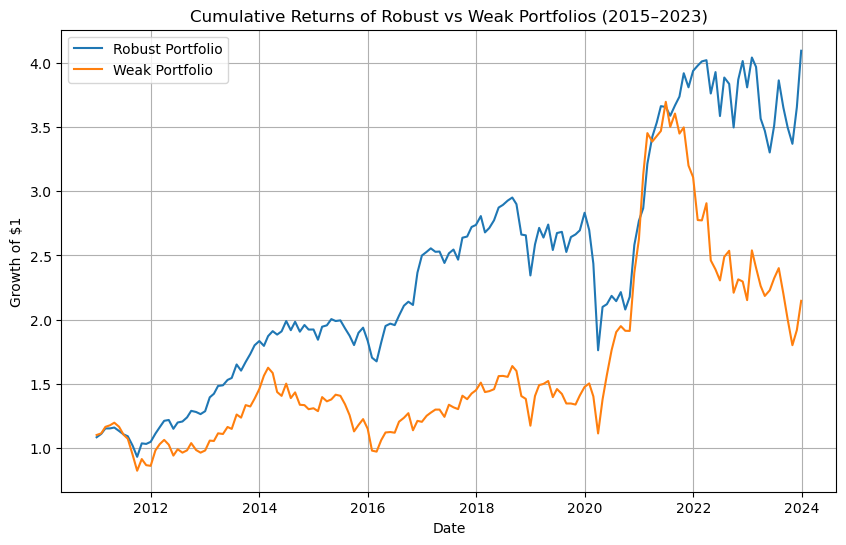

In [55]:
kept = compustat_2014[["LPERMNO", "profit_group"]].rename(columns={"LPERMNO": "PERMNO"})
crsp_labeled = crsp_cleaned.merge(kept, on="PERMNO", how="inner")

robust_returns = (
    crsp_labeled[crsp_labeled["profit_group"] == "robust"]
    .groupby("date")["RET"]
    .mean()
)

weak_returns = (
    crsp_labeled[crsp_labeled["profit_group"] == "weak"]
    .groupby("date")["RET"]
    .mean()
)

robust_cum = (1 + robust_returns).cumprod()
weak_cum = (1 + weak_returns).cumprod()

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(robust_cum.index, robust_cum.values, label="Robust Portfolio")
plt.plot(weak_cum.index, weak_cum.values, label="Weak Portfolio")

plt.title("Cumulative Returns of Robust vs Weak Portfolios (2015–2023)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True)
plt.show()

The robust portfolio performed significantly better than the weak portfolio from 2015 to 2023.
A $1 investment in robust firms grew much faster, while the weak portfolio remained flat or volatile.
This suggests that high-profitability firms tend to outperform low-profitability firms in the long run.

# Part D

In [58]:
compustat_cleaned["datadate"] = pd.to_datetime(compustat_cleaned["datadate"])
compustat_2023 = compustat_cleaned[compustat_cleaned["datadate"] == "2023-12-31"].copy()

compustat_2023["op_margin"] = compustat_2023["oibdp"] / compustat_2023["sale"]

bottom_1 = compustat_2023["op_margin"].quantile(0.25)
top_1 = compustat_2023["op_margin"].quantile(0.75)

def classify(x):
    if x >= top_1:
        return "Robust"
    elif x <= bottom_1:
        return "Weak"
    else:
        return "Moderate"

compustat_2023["profit_2023"] = compustat_2023["op_margin"].apply(classify)

labels_2014 = compustat_2014[["LPERMNO", "profit_group"]].rename(
    columns={"LPERMNO": "PERMNO", "profit_group": "profit_2014"}
)

labels_2023 = compustat_2023[["LPERMNO", "profit_2023"]].rename(
    columns={"LPERMNO": "PERMNO"}
)

combined = labels_2014.merge(labels_2023, on="PERMNO", how="outer")
combined.head()

/var/folders/72/jzgv8vwj1vg99xmfly5xkxz00000gn/T/ipykernel_42269/1633375665.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  compustat_cleaned["datadate"] = pd.to_datetime(compustat_cleaned["datadate"])


,PERMNO,profit_2014,profit_2023
0,21020,moderate,Moderate
1,11499,moderate,Moderate
2,27991,robust,Robust
3,10517,robust,Robust
4,20482,moderate,Moderate


In [66]:
table = pd.crosstab(
    combined["profit_2014"].fillna("NaN"),
    combined["profit_2023"].fillna("NaN"),
    dropna=False
)

table

profit_2023,Moderate,NaN,Robust,Weak
profit_2014,,,,
NaN,526,0,205,594
moderate,729,581,149,20
robust,59,303,372,6
weak,181,407,23,129


In [75]:
tmp = combined.copy()
tmp["p14"] = tmp["profit_2014"].str.lower()
tmp["p23"] = tmp["profit_2023"].str.lower()

both = tmp[tmp["p14"].notna() & tmp["p23"].notna()]

changed = (both["p14"] != both["p23"]).sum()
disappeared = (tmp["profit_2014"].notna() & tmp["profit_2023"].isna()).sum()
new_firms = (tmp["profit_2014"].isna() & tmp["profit_2023"].notna()).sum()

print(both)
print("Number of firms changed:", changed)
print("Number of firms disappeared:", disappeared)
print("Number of new firms:", new_firms)

      PERMNO profit_2014 profit_2023       p14       p23
0      21020    moderate    Moderate  moderate  moderate
1      11499    moderate    Moderate  moderate  moderate
2      27991      robust      Robust    robust    robust
3      10517      robust      Robust    robust    robust
4      20482    moderate    Moderate  moderate  moderate
...      ...         ...         ...       ...       ...
2951   13279        weak        Weak      weak      weak
2955   82678        weak    Moderate      weak  moderate
2956   12615    moderate    Moderate  moderate  moderate
2957   14060        weak        Weak      weak      weak
2958   14406    moderate    Moderate  moderate  moderate

[1668 rows x 5 columns]
Number of firms changed: 438
Number of firms disappeared: 1291
Number of new firms: 1325


438 firms changed categories.
1291 firms disappeared.
1325 firms appeared.

The result shows that not rebalancing leads to strong portfolio drift. Profitability classifications shift over time, and many firms enter or exit the market, so the original robust and weak portfolios do not remain stable. Regular rebalancing would be necessary to maintain the intended exposure.

# Part E

In [80]:
five = compustat_cleaned[
    (compustat_cleaned["datadate"] >= "2010-01-01") & (compustat_cleaned["datadate"] <= "2014-12-31")].copy()

five["op_margin"] = five["oibdp"] / five["sale"]

counts = five.groupby("LPERMNO")["op_margin"].count()
valid = counts[counts == 5].index

five_valid = five[five["LPERMNO"].isin(valid)]

mean_margin = five_valid.groupby("LPERMNO")["op_margin"].mean().reset_index()
mean_margin = mean_margin.rename(columns = {"op_margin": "op_margin_5yr"})

q25 = mean_margin["op_margin_5yr"].quantile(0.25)
q75 = mean_margin["op_margin_5yr"].quantile(0.75)

def cls(x):
    if x >= q75:
        return "robust"
    elif x <= q25:
        return "weak"
    else:
        return "moderate"

mean_margin["profit_5yr"] = mean_margin["op_margin_5yr"].apply(cls)

E_compare = labels_2014.merge(mean_margin.rename(columns = {"LPERMNO":"PERMNO"}), on = "PERMNO", how = "outer")

cats = ["moderate", "robust", "weak", "NaN"]

p14 = E_compare["profit_2014"].fillna("NaN").astype("category").cat.set_categories(cats)
p5 = E_compare["profit_5yr"].fillna("NaN").astype("category").cat.set_categories(cats)

table_E = pd.crosstab(
    p14,
    p5,
    dropna=False
)


drop_5yr = E_compare["op_margin_5yr"].isna().sum()
change_5yr = (
    E_compare[E_compare["op_margin_5yr"].notna() & E_compare["profit_2014"].notna()]["profit_2014"].str.lower().values
    !=
    E_compare[E_compare["op_margin_5yr"].notna() & E_compare["profit_2014"].notna()]["profit_5yr"].values
).sum()

print(table_E)
print("Number of changed:", change_5yr)
print("Number of dropped:", drop_5yr)

profit_5yr   moderate  robust  weak  NaN
profit_2014                             
moderate          989      98   138  254
robust             63     501    11  165
weak               38       3   376  323
NaN               258      73   150    0
Number of changed: 351
Number of dropped: 742


Using 5-year average operating margins produces clear different classifications compared with using only the 2014 operating margin.
351 firms changed categories, which shows that multi-year profitability smooths out temporary shocks and moves many firms out of the extreme “robust” or “weak” groups.

742 firms were dropped because they did not have complete operating-margin data for all five years. This highlights the trade-off in multi-year averaging: it produces more stable classifications but significantly reduces the size of the investable universe.